In [1]:
from src.database import get_database

db = get_database()

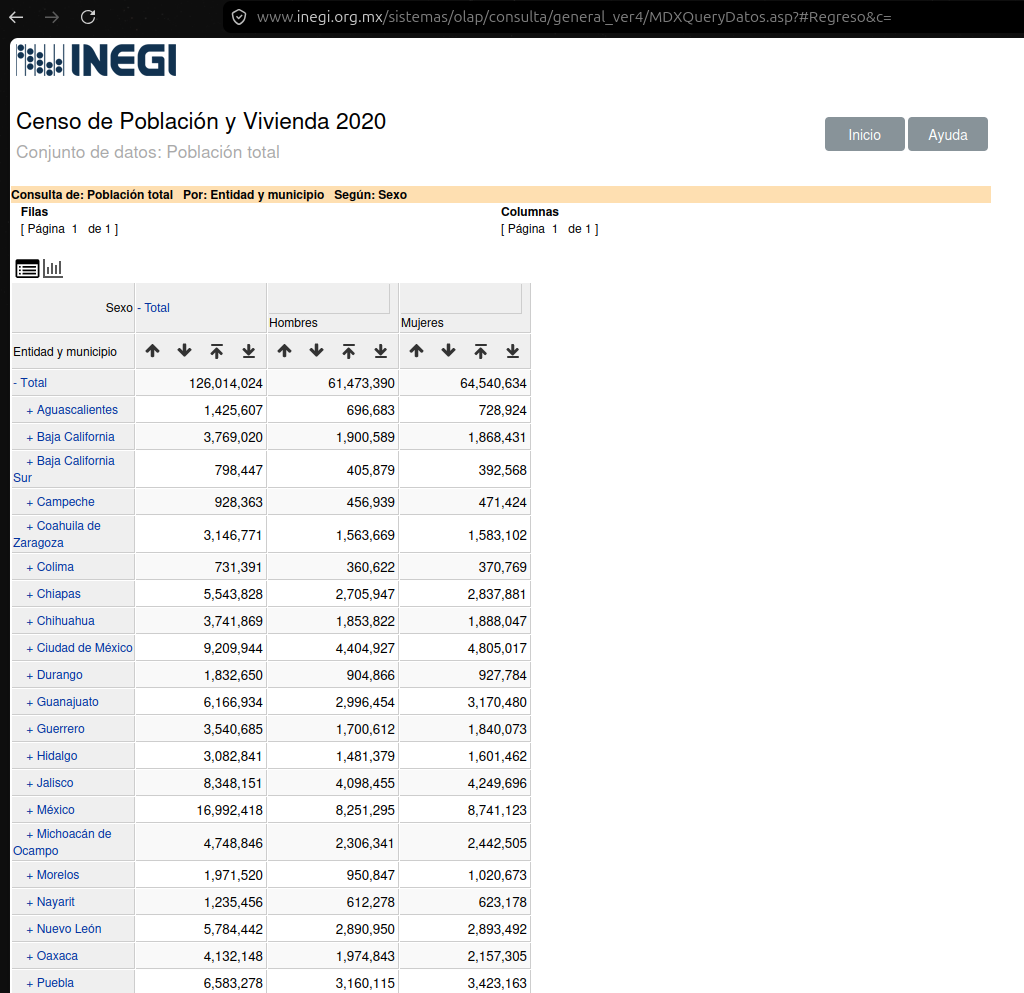

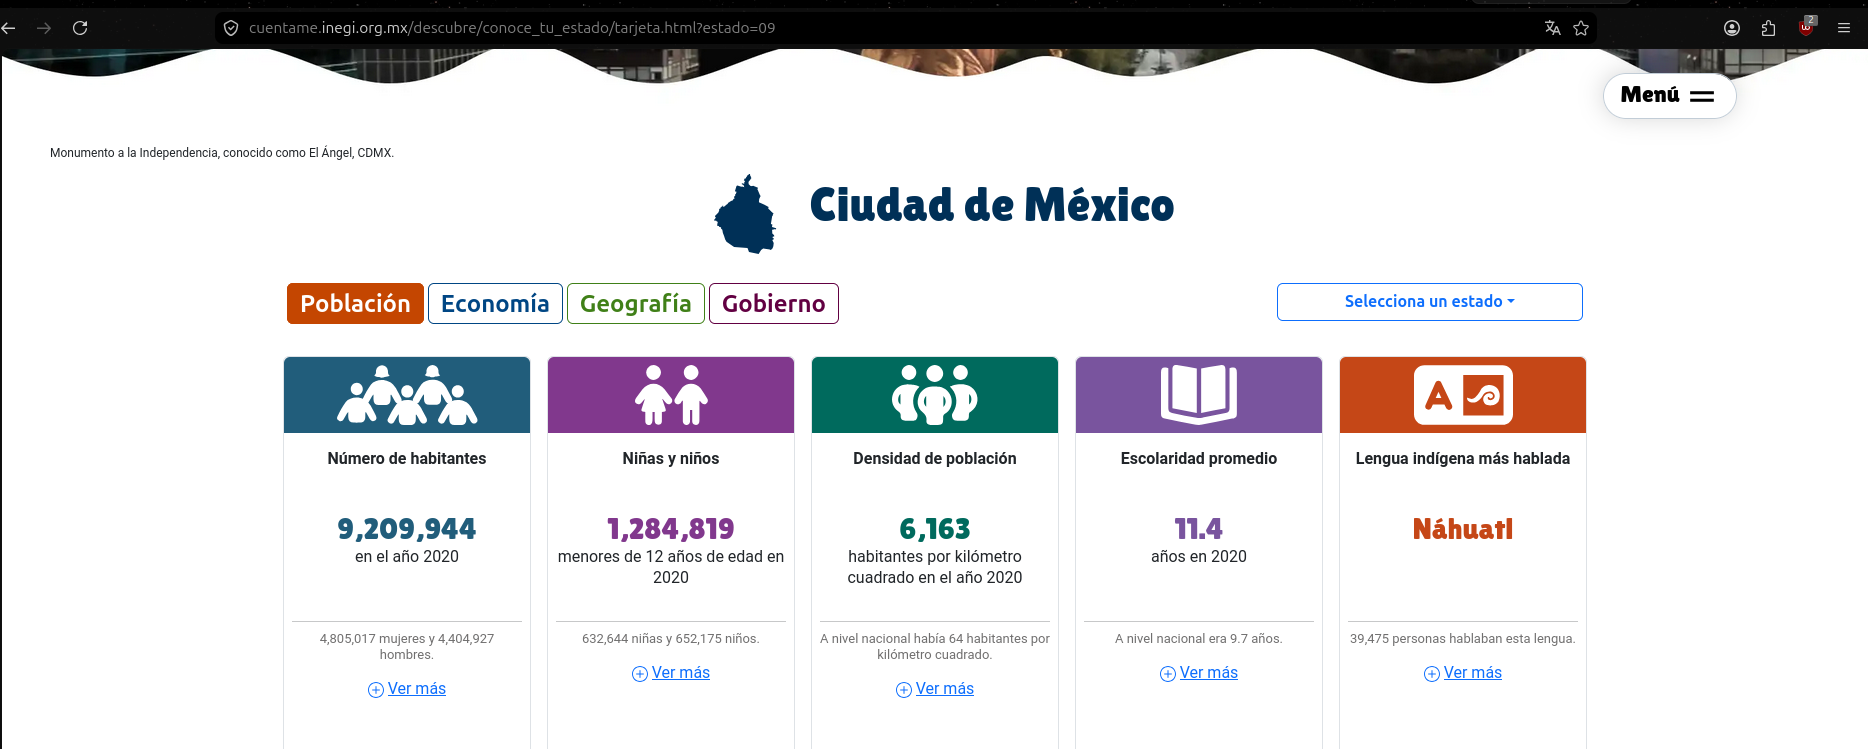

In [5]:
import polars as pl
from pathlib import Path
output_file = Path.cwd().parent / "data" / "polars" / "mexico_city_covid_data_dates.parquet"
schema = (pl.read_parquet_schema(output_file))
for column_name, dtype in schema.items():
    print(f"Columna: {column_name}, Tipo de dato: {dtype}")

Columna: _id, Tipo de dato: Binary
Columna: ASMA, Tipo de dato: String
Columna: CARDIOVASCULAR, Tipo de dato: String
Columna: CLASIFICACION_FINAL_COVID, Tipo de dato: String
Columna: CLASIFICACION_FINAL_FLU, Tipo de dato: String
Columna: DIABETES, Tipo de dato: String
Columna: EDAD, Tipo de dato: Int64
Columna: EMBARAZO, Tipo de dato: String
Columna: ENTIDAD_NAC, Tipo de dato: String
Columna: ENTIDAD_RES, Tipo de dato: String
Columna: ENTIDAD_UM, Tipo de dato: String
Columna: EPOC, Tipo de dato: String
Columna: FECHA_DEF, Tipo de dato: Date
Columna: FECHA_INGRESO, Tipo de dato: Date
Columna: FECHA_SINTOMAS, Tipo de dato: Date
Columna: HABLA_LENGUA_INDIG, Tipo de dato: String
Columna: HIPERTENSION, Tipo de dato: String
Columna: INDIGENA, Tipo de dato: String
Columna: INMUSUPR, Tipo de dato: String
Columna: INTUBADO, Tipo de dato: String
Columna: MIGRANTE, Tipo de dato: String
Columna: MUNICIPIO_RES, Tipo de dato: String
Columna: NACIONALIDAD, Tipo de dato: String
Columna: NEUMONIA, Tipo

In [10]:
primer_registro = pl.scan_parquet(output_file).head(1).collect()
print(primer_registro.to_dict())


{'_id': shape: (1,)
Series: '_id' [binary]
[
	b"`:\x7f\xd9\x07\x7f\x00\x00"
], 'ASMA': shape: (1,)
Series: 'ASMA' [str]
[
	"2"
], 'CARDIOVASCULAR': shape: (1,)
Series: 'CARDIOVASCULAR' [str]
[
	"2"
], 'CLASIFICACION_FINAL_COVID': shape: (1,)
Series: 'CLASIFICACION_FINAL_COVID' [str]
[
	"7"
], 'CLASIFICACION_FINAL_FLU': shape: (1,)
Series: 'CLASIFICACION_FINAL_FLU' [str]
[
	"6"
], 'DIABETES': shape: (1,)
Series: 'DIABETES' [str]
[
	"2"
], 'EDAD': shape: (1,)
Series: 'EDAD' [i64]
[
	51
], 'EMBARAZO': shape: (1,)
Series: 'EMBARAZO' [str]
[
	"97"
], 'ENTIDAD_NAC': shape: (1,)
Series: 'ENTIDAD_NAC' [str]
[
	"09"
], 'ENTIDAD_RES': shape: (1,)
Series: 'ENTIDAD_RES' [str]
[
	"09"
], 'ENTIDAD_UM': shape: (1,)
Series: 'ENTIDAD_UM' [str]
[
	"09"
], 'EPOC': shape: (1,)
Series: 'EPOC' [str]
[
	"2"
], 'FECHA_DEF': shape: (1,)
Series: 'FECHA_DEF' [date]
[
	null
], 'FECHA_INGRESO': shape: (1,)
Series: 'FECHA_INGRESO' [date]
[
	2020-08-18
], 'FECHA_SINTOMAS': shape: (1,)
Series: 'FECHA_SINTOMAS' [date]

In [ ]:
from pathlib import Path
import polars as pl

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data" / "polars"
input_file = DATA_DIR / "mexico_city_covid_data_dates.parquet"

# POBLACIÓN OFICIAL CDMX (CENSO 2020)
POB_TOTAL = 9_209_944
POB_HOMBRES = 4_404_927
POB_MUJERES = 4_805_017


df_defunciones = (
    pl.scan_parquet(input_file)
    .filter(
        (pl.col("ENTIDAD_RES") == "09") & 
        (pl.col("FECHA_DEF").is_not_null())
    )
)

df_conteos = (
    df_defunciones
    .group_by("SEXO")
    .agg(pl.len().alias("MUERTES"))
    .collect()
)

#Muertes por la categoría de sexo
print(df_conteos)



shape: (2, 2)
┌──────┬─────────┐
│ SEXO ┆ MUERTES │
│ ---  ┆ ---     │
│ str  ┆ u32     │
╞══════╪═════════╡
│ 2    ┆ 37191   │
│ 1    ┆ 22576   │
└──────┴─────────┘


In [16]:
muertes_mujeres = df_conteos.filter(pl.col("SEXO") == "1")["MUERTES"][0]
muertes_hombres = df_conteos.filter(pl.col("SEXO") == "2")["MUERTES"][0]
muertes_totales = muertes_mujeres + muertes_hombres

tasa_general = (muertes_totales / POB_TOTAL) * 100
tasa_hombres = (muertes_hombres / POB_HOMBRES) * 100
tasa_mujeres = (muertes_mujeres / POB_MUJERES) * 100

print(f"Tasa de Mortalidad General: {tasa_general:.4f} %")
print(f"Tasa de Mortalidad Hombres: {tasa_hombres:.4f} %")
print(f"Tasa de Mortalidad Mujeres: {tasa_mujeres:.4f} %")

Tasa de Mortalidad General: 0.6489 %
Tasa de Mortalidad Hombres: 0.8443 %
Tasa de Mortalidad Mujeres: 0.4698 %
